**Project Customer Segmentation - Clustering**

**Dataset:** `Mall_Customers.csv`


**1. Setup**

In [1]:
%pip install -q numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [4]:
# configurations
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")
sns.set_theme(style="darkgrid")

plt.rcParams.update({
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8
})

RANDOM_STATE = 42
CSV_PATH = "Mall_Customers.csv"          # update path for a different dataset

**2. Load Data**

In [5]:
df = pd.read_csv(CSV_PATH)

In [6]:
print("Shape:", df.shape)

Shape: (200, 5)


In [7]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**3. Exploratory Data Analysis (EDA)**

In [9]:
# save CustomerID to a list for later use
customer_id = df["CustomerID"]

In [10]:
customer_id.head()

0    1
1    2
2    3
3    4
4    5
Name: CustomerID, dtype: int64

In [11]:
# drop CustomerID column as it is not useful for modelling
df = df.drop(columns=["CustomerID"])

In [12]:
# basic dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Gender                  200 non-null    object
 1   Age                     200 non-null    int64 
 2   Annual Income (k$)      200 non-null    int64 
 3   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(3), object(1)
memory usage: 6.4+ KB


In [13]:
# missing values
df.isnull().sum()

Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [14]:
# check for encoded missing values
for col in df.columns:
    print(df[col].value_counts().head(10))

Gender
Female    112
Male       88
Name: count, dtype: int64
Age
32    11
35     9
31     8
19     8
30     7
49     7
23     6
40     6
36     6
27     6
Name: count, dtype: int64
Annual Income (k$)
54    12
78    12
60     6
48     6
63     6
71     6
62     6
87     6
40     4
43     4
Name: count, dtype: int64
Spending Score (1-100)
42    8
55    7
73    6
46    6
48    5
52    5
50    5
59    5
75    5
35    5
Name: count, dtype: int64


In [15]:
# duplicates
duplicate_mask = df.duplicated()
num_duplicates = duplicate_mask.sum()
print("Number of duplicate rows:", num_duplicates)

# (optional) drop duplicates if present
# df = df.drop_duplicates()
# print("Shape after dropping duplicates:", df.shape)

Number of duplicate rows: 0


**Data Visualization**

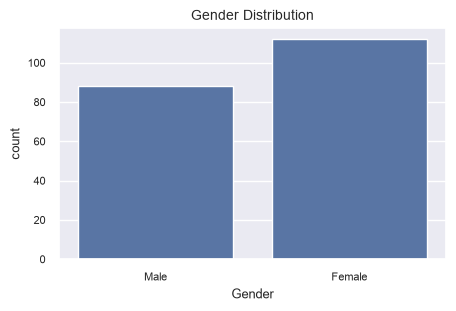

In [16]:
# Gender distribution
plt.figure(figsize=(5, 3))
sns.countplot(x="Gender", data=df)
plt.title("Gender Distribution")
plt.show()

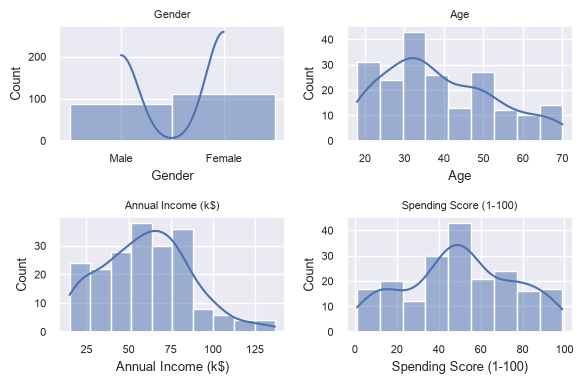

In [17]:
# histogram plot - distribution
fig, axes = plt.subplots(2, 2, figsize=(6, 4))
axes = axes.flatten()

for i, col in enumerate(df.columns):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(col, fontsize=8)

plt.tight_layout()
plt.show() 

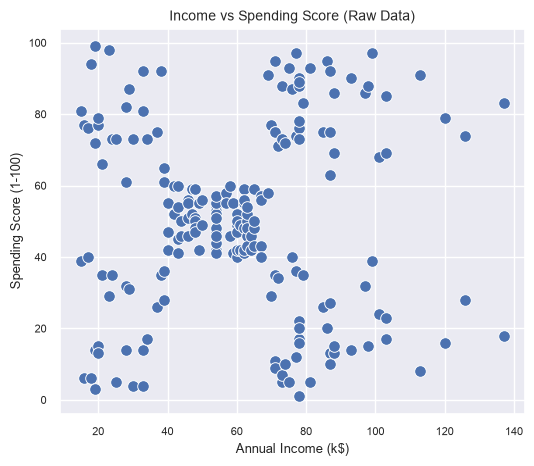

In [18]:
# scatter plot: Income vs Spending
plt.figure(figsize=(6, 5))
sns.scatterplot(
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    data=df,
    s=70
)
plt.title("Income vs Spending Score (Raw Data)")
plt.show()

**Inference: We can clearly see clusters in this plot**

**4. Data Preprocessing**

In [19]:
df.columns

Index(['Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)'], dtype='object')

In [20]:
# feature selection
columns_to_select = ["Annual Income (k$)", "Spending Score (1-100)"]

X = df[columns_to_select]

In [21]:
# scale the features (K-means is distance-based)
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [22]:
X_scaled[:5]

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992]])

**5. Elbow method - WCSS**

(Find best k value)

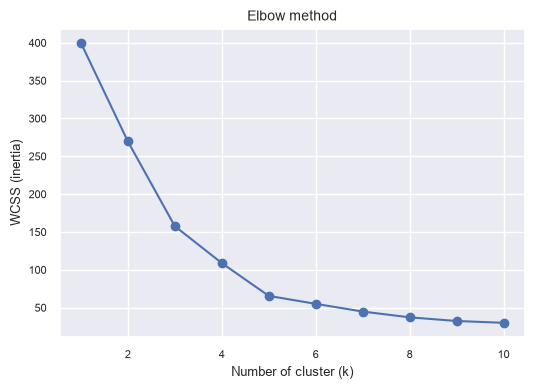

In [26]:
wcss = []
k_range = range(1,11)

for k in k_range:
    kmeans = KMeans(n_clusters=k,random_state=RANDOM_STATE, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(6,4))
plt.plot(list(k_range), wcss, marker="o")
plt.xlabel("Number of cluster (k)")
plt.ylabel("WCSS (inertia)")
plt.title("Elbow method")
plt.show()    

In [27]:
wcss


[400.0,
 269.6910121927639,
 157.70400815035947,
 108.92131661364357,
 65.56840815571682,
 55.057348270386,
 44.86475569922556,
 37.22818767758588,
 32.39226763033116,
 29.981897788243693]

**Key observations:**
- Very steep drop from K = 1 → 2 → 3
- Still a noticeable improvement till K = 4
- After K = 5, the curve starts flattening
- From K = 6 onward, the reduction in WCSS is marginal

📌 This clear change in slope around K = 5 is the elbow point.

6. K-Means Clustering